# SV & indel-SNP tagging (corrected) — new panel vs GrENE-Net short-read SNPs

**Unit of analysis (project rule since 2026-10-01): SV anchors are Truvari EVENTS, not alleles.** An event's anchor vector is the union over its member alleles (carries any / called at any); data from `r3_persite_gwas/build_tagging_events.py`. Short indels stay one anchor per record. The record-based SV numbers are printed once in §1 for reference only. §2-3 now cover the whole filter grid: anchor MAF floor (MAC&ge;2, 0.01, 0.05, 0.10) x anchor call rate (none, 50, 70, 90%).

**Replaces** `sv_snp_ld_tagging.ipynb` / `build_sv_snp_ld.py`, which had two bugs
found while reviewing its plots:

1. **Missingness silently coded as REF.** The original loader only used
   `var_pa` (ALT-carrier), never `var_called` (the called mask) -- so a
   missing genotype and a true REF call were indistinguishable, for both the
   anchor (SV/indel) and the candidate SNP. Panel SV records average ~60%
   missing (`panel_stats_arch3.ipynb` &sect;5), and missingness is strongly
   cohort-correlated (long-read vs short-read), so jointly-missing founders
   could inflate apparent agreement.
2. **No MAC floor.** 53.5% of SVs are singletons (MAC=1) -- a singleton
   anchor can register a spurious r&sup2;=1 "tag" against any other marker
   private to the exact same one founder, a small-N coincidence, not real LD.

Confirmed empirically that the GrENE-Net short-read VCF has **zero missing
genotypes** (sampled ~2M GT calls), so only the new-panel side needed
masking. Fixed in `analysis/grenenet_selection/r3_persite_gwas/build_tagging_masked.py`: proper
pairwise-complete masked r&sup2; (vectorized via matrix-vector products, not a
per-SNP loop) + a configurable MAC floor (default &ge;2, i.e. drop singletons)
applied to both the anchor and every candidate SNP. Extended to **indels**
(not just SVs), and every anchor's own `ac`/`an`/`maf` is stored, so the
missingness-filter and MAF-filter sensitivity plots below are computed
post-hoc from one set of `--mac-floor 2` runs -- no separate compute per filter.


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJ = "/global/scratch/users/tbellg/kmate"
V2 = f"{PROJ}/analysis/grenenet_selection/r3_persite_gwas/results/sv_snp_ld_v2"
PLOTDIR = f"{PROJ}/analysis/grenenet_selection/notebooks/plots"
CHROMS = ["Chr1", "Chr2", "Chr3", "Chr4", "Chr5"]
NF = 231

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110})

CLASS_ORDER = ["SV", "indel"]
ACCENT = "#2a78d6"   # arch3 panel SNPs
BASE   = "#7f8da6"   # GrENE-Net short-read SNPs
INK_MUTED = "#898781"

frames = []
# SV anchors are Truvari EVENTS (project rule since 2026-10-01; build_tagging_events.py); short indels stay records.
for cls_key, cls_label in [("svevent", "SV"), ("indel", "indel")]:
    for chrom in CHROMS:
        zp = np.load(f"{V2}/tagging_{cls_key}_panel_{chrom}.npz", allow_pickle=True)
        zs = np.load(f"{V2}/tagging_{cls_key}_shortread_{chrom}.npz", allow_pickle=True)
        assert np.array_equal(zp["pos"], zs["pos"])
        frames.append(pd.DataFrame({
            "cls": cls_label, "chrom": chrom, "pos": zp["pos"], "size": zp["size"],
            "ac": zp["ac"], "an": zp["an"], "maf": zp["maf"],
            "r2_panel": zp["best_r2"], "r2_shortread": zs["best_r2"],
        }))
df = pd.concat(frames, ignore_index=True)
df["miss_pct"] = 100 * (1 - df.an / NF)
df["callrate"] = 100 * df.an / NF
df["mac"] = np.minimum(df.ac, df.an - df.ac)

# reference only: the superseded record-based (allele) SV anchors
old_rows = []
for chrom in CHROMS:
    zp = np.load(f"{V2}/tagging_sv_panel_{chrom}.npz", allow_pickle=True); zs = np.load(f"{V2}/tagging_sv_shortread_{chrom}.npz", allow_pickle=True)
    old_rows.append(pd.DataFrame({"r2_panel": zp["best_r2"], "r2_shortread": zs["best_r2"]}))
old_sv = pd.concat(old_rows, ignore_index=True)

print(f"{len(df):,} anchors genome-wide (MAC>=2): SV EVENTS and indel records")
print(df.cls.value_counts().rename("n"))
print(f"\nmedian anchor missingness: SV {df.loc[df.cls=='SV','miss_pct'].median():.1f}%, "
      f"indel {df.loc[df.cls=='indel','miss_pct'].median():.1f}%")

1,466,227 anchors genome-wide (MAC>=2): SV EVENTS and indel records
cls
indel    1406721
SV         59506
Name: n, dtype: int64



median anchor missingness: SV 16.9%, indel 8.7%


## 1. Corrected headline tagging rate (survival curve)

% of TESTABLE anchors (best r2 defined: a SNP in the window with >= 50% of founders jointly called) with r2 > t
threshold         0.20  0.50  0.80  0.95
cls   snp_source                        
SV    panel       99.8  95.9  86.5  77.3
      shortread   97.4  81.3  55.7  38.1
indel panel       99.4  88.9  75.0  66.7
      shortread   97.4  77.7  54.2  37.1

same, but untestable anchors counted as untagged (denominator = all MAC>=2 anchors)
threshold         0.20  0.50  0.80  0.95
cls   snp_source                        
SV    panel       81.5  78.3  70.5  63.0
      shortread   79.4  66.2  45.4  31.1
indel panel       91.3  81.7  68.9  61.2
      shortread   89.4  71.4  49.7  34.1



untestable anchors (%): {'SV': 18.4, 'indel': 8.1} (panel SNPs)

for reference, the superseded record-based (allele) SV anchors, same MAC>=2 floor:
{'panel': [86.9, 81.2, 69.7, 63.3], 'shortread': [85.1, 69.0, 47.8, 38.8]} (n=105,315 records vs 59,506 events)


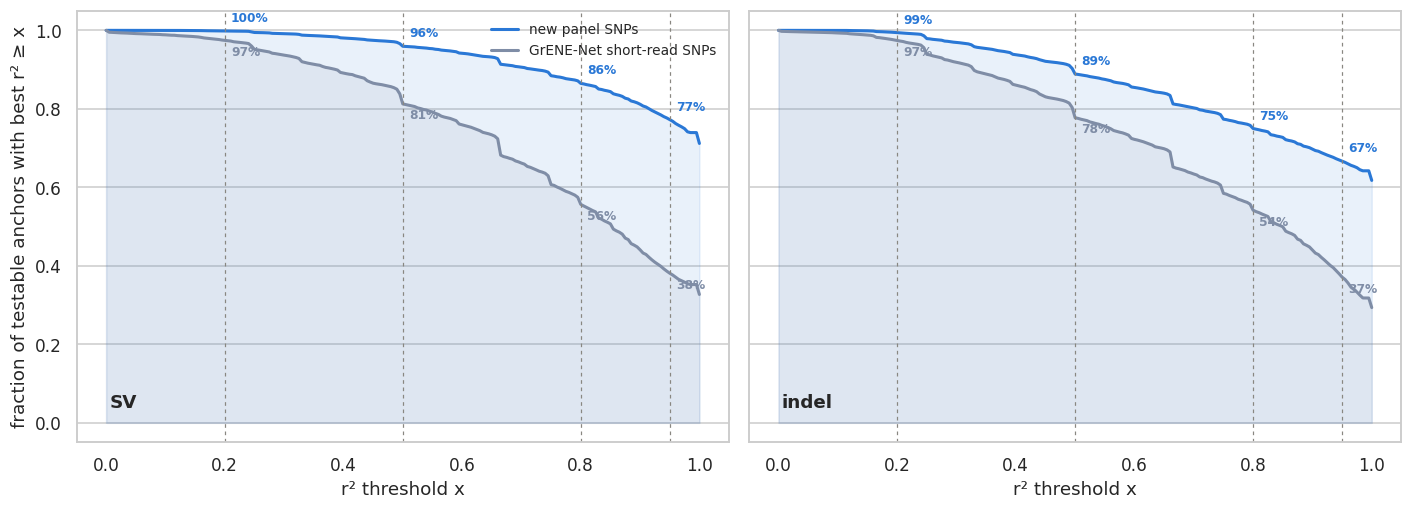

In [2]:
# 1. Corrected headline tagging rate, SV vs indel, panel vs shortread
# (compare to the OLD buggy numbers, computed without masking/MAC-floor: SV panel/shortread
#  85.8%/47.4% at r2>0.8 -- see sv_snp_ld_tagging.ipynb, now archived/superseded)
rows = []
for cl in CLASS_ORDER:
    sub = df[df.cls == cl]
    for mode, col in [("panel", "r2_panel"), ("shortread", "r2_shortread")]:
        for t in (0.2, 0.5, 0.8, 0.95):
            rows.append({"cls": cl, "snp_source": mode, "threshold": t, "pct": 100*(sub[col].dropna() > t).mean(),
                         "pct_all": 100*(sub[col] > t).mean()})
headline = pd.DataFrame(rows)
print("% of TESTABLE anchors (best r2 defined: a SNP in the window with >= 50% of founders jointly called) with r2 > t")
print(headline.pivot_table(index=["cls", "snp_source"], columns="threshold", values="pct").round(1))
print("\nsame, but untestable anchors counted as untagged (denominator = all MAC>=2 anchors)")
print(headline.pivot_table(index=["cls", "snp_source"], columns="threshold", values="pct_all").round(1))
print("\nuntestable anchors (%):", {cl: round(100*df[df.cls==cl].r2_panel.isna().mean(), 1) for cl in CLASS_ORDER}, "(panel SNPs)")
print("\nfor reference, the superseded record-based (allele) SV anchors, same MAC>=2 floor:")
print({m: [round(100*(old_sv[c] > t).mean(), 1) for t in (0.2, 0.5, 0.8, 0.95)] for m, c in [("panel", "r2_panel"), ("shortread", "r2_shortread")]},
      f"(n={len(old_sv):,} records vs {int((df.cls=='SV').sum()):,} events)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
xs = np.linspace(0, 1, 201)
for ax, cl in zip(axes, CLASS_ORDER):
    sub = df[df.cls == cl]
    _p, _s = sub.r2_panel.dropna(), sub.r2_shortread.dropna()          # testable anchors, per SNP source
    surv_panel = np.array([(_p >= x).mean() for x in xs])
    surv_short = np.array([(_s >= x).mean() for x in xs])
    ax.plot(xs, surv_panel, color=ACCENT, lw=2, label="new panel SNPs")
    ax.fill_between(xs, surv_panel, color=ACCENT, alpha=0.10)
    ax.plot(xs, surv_short, color=BASE, lw=2, label="GrENE-Net short-read SNPs")
    ax.fill_between(xs, surv_short, color=BASE, alpha=0.10)
    for t in (0.2, 0.5, 0.8, 0.95):
        ax.axvline(t, color=INK_MUTED, lw=0.8, ls=(0, (3, 3)))
        jp = np.argmin(np.abs(xs - t)); js = jp
        ax.annotate(f"{100*surv_panel[jp]:.0f}%", (t, surv_panel[jp]), xytext=(4, 6),
                    textcoords="offset points", fontsize=8, color=ACCENT, fontweight="bold")
        ax.annotate(f"{100*surv_short[js]:.0f}%", (t, surv_short[js]), xytext=(4, -10),
                    textcoords="offset points", fontsize=8, color=BASE, fontweight="bold")
    ax.annotate(cl, xy=(0.05, 0.08), xycoords="axes fraction", fontweight="bold")
    ax.set_xlabel("r² threshold x")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("fraction of testable anchors with best r² ≥ x")
axes[0].legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(f"{PLOTDIR}/tagging_01_survival_curve.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Missingness-filter sensitivity

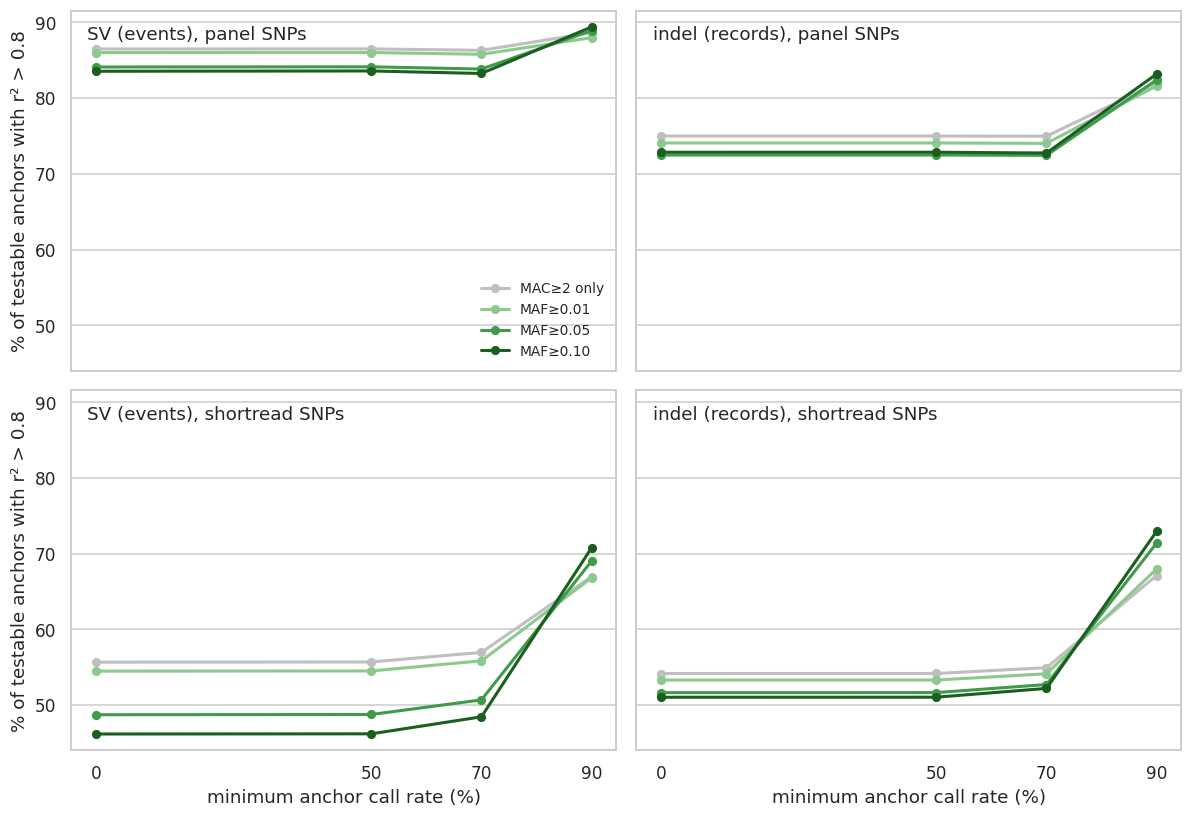

anchors kept (SV events), rows = MAF floor, columns = min call rate %
min_callrate     0      50     70     90
maf_floor                               
0.00          59506  48523  46264  18397
0.01          55201  44218  41959  14796
0.05          27277  20332  19182   6789
0.10          17653  13288  12512   4138

of which testable (panel SNPs)
min_callrate     0      50     70     90
maf_floor                               
0.00          48542  48523  46264  18397
0.01          44237  44218  41959  14796
0.05          20345  20332  19182   6789
0.10          13295  13288  12512   4138

% of testable anchors tagged (r2>0.8), SV events, new panel SNPs
min_callrate    0     50    70    90
maf_floor                           
0.00          86.5  86.5  86.3  88.6
0.01          86.0  86.0  85.8  88.0
0.05          84.1  84.1  83.8  88.9
0.10          83.5  83.6  83.2  89.4

% of testable anchors tagged (r2>0.8), SV events, short-read SNPs
min_callrate    0     50    70    90
maf_floor     

In [3]:
# 2. Call-rate filter on the anchor, one line per MAF floor. SV anchors are EVENTS (call = union of members).
# Base = MAC>=2 (compute-time floor). MAF floor = min(ac, an-ac)/an on the anchor's called founders.
# call rate = % of the 231 founders called at the anchor. A NaN best r2 (no testable SNP / < 50% jointly called)
# is EXCLUDED from the denominator here: anchors with < 50% call rate cannot be tested, so counting them as
# "untagged" would make any call-rate filter look like an improvement by construction.
CALL = [0, 50, 70, 90]                       # min call rate (%)
MAFS = [(0.0, "MAC≥2 only"), (0.01, "MAF≥0.01"), (0.05, "MAF≥0.05"), (0.10, "MAF≥0.10")]
MAFCOL = dict(zip([m for m, _ in MAFS], ["#BFBFBF", "#8CC98C", "#3F9B49", "#1B5E20"]))
rows = []
for cl in CLASS_ORDER:
    for mode, col in [("panel", "r2_panel"), ("shortread", "r2_shortread")]:
        sub = df[df.cls == cl]
        for maf_f, _ in MAFS:
            for cr in CALL:
                keep = sub[(sub.maf >= maf_f) & (sub.callrate >= cr)]
                rows.append({"cls": cl, "snp_source": mode, "maf_floor": maf_f, "min_callrate": cr,
                             "pct_tagged": 100*(keep[col].dropna() > 0.8).mean() if keep[col].notna().any() else np.nan,
                             "n": len(keep), "n_testable": int(keep[col].notna().sum())})
filt = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), sharey=True, sharex=True)
for i, mode in enumerate(["panel", "shortread"]):
    for j, cl in enumerate(CLASS_ORDER):
        ax = axes[i, j]
        for maf_f, lab in MAFS:
            sub = filt[(filt.cls == cl) & (filt.snp_source == mode) & (filt.maf_floor == maf_f)].sort_values("min_callrate")
            ax.plot(sub.min_callrate, sub.pct_tagged, "-o", color=MAFCOL[maf_f], lw=2, ms=5, label=lab)
        ax.annotate(f"{cl} ({'events' if cl == 'SV' else 'records'}), {mode} SNPs", xy=(0.03, 0.92), xycoords="axes fraction")
        ax.grid(axis="x", visible=False); ax.set_xticks(CALL)
axes[1, 0].set_xlabel("minimum anchor call rate (%)"); axes[1, 1].set_xlabel("minimum anchor call rate (%)")
axes[0, 0].set_ylabel("% of testable anchors with r² > 0.8"); axes[1, 0].set_ylabel("% of testable anchors with r² > 0.8")
axes[0, 0].legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(f"{PLOTDIR}/tagging_02_callrate_by_maf.png", dpi=150, bbox_inches="tight"); plt.show()
print("anchors kept (SV events), rows = MAF floor, columns = min call rate %")
print(filt[(filt.cls == "SV") & (filt.snp_source == "panel")].pivot_table(index="maf_floor", columns="min_callrate", values="n").astype(int))
print("\nof which testable (panel SNPs)")
print(filt[(filt.cls == "SV") & (filt.snp_source == "panel")].pivot_table(index="maf_floor", columns="min_callrate", values="n_testable").astype(int))
print("\n% of testable anchors tagged (r2>0.8), SV events, new panel SNPs")
print(filt[(filt.cls == "SV") & (filt.snp_source == "panel")].pivot_table(index="maf_floor", columns="min_callrate", values="pct_tagged").round(1))
print("\n% of testable anchors tagged (r2>0.8), SV events, short-read SNPs")
print(filt[(filt.cls == "SV") & (filt.snp_source == "shortread")].pivot_table(index="maf_floor", columns="min_callrate", values="pct_tagged").round(1))

## 3. MAF/MAC-filter sensitivity

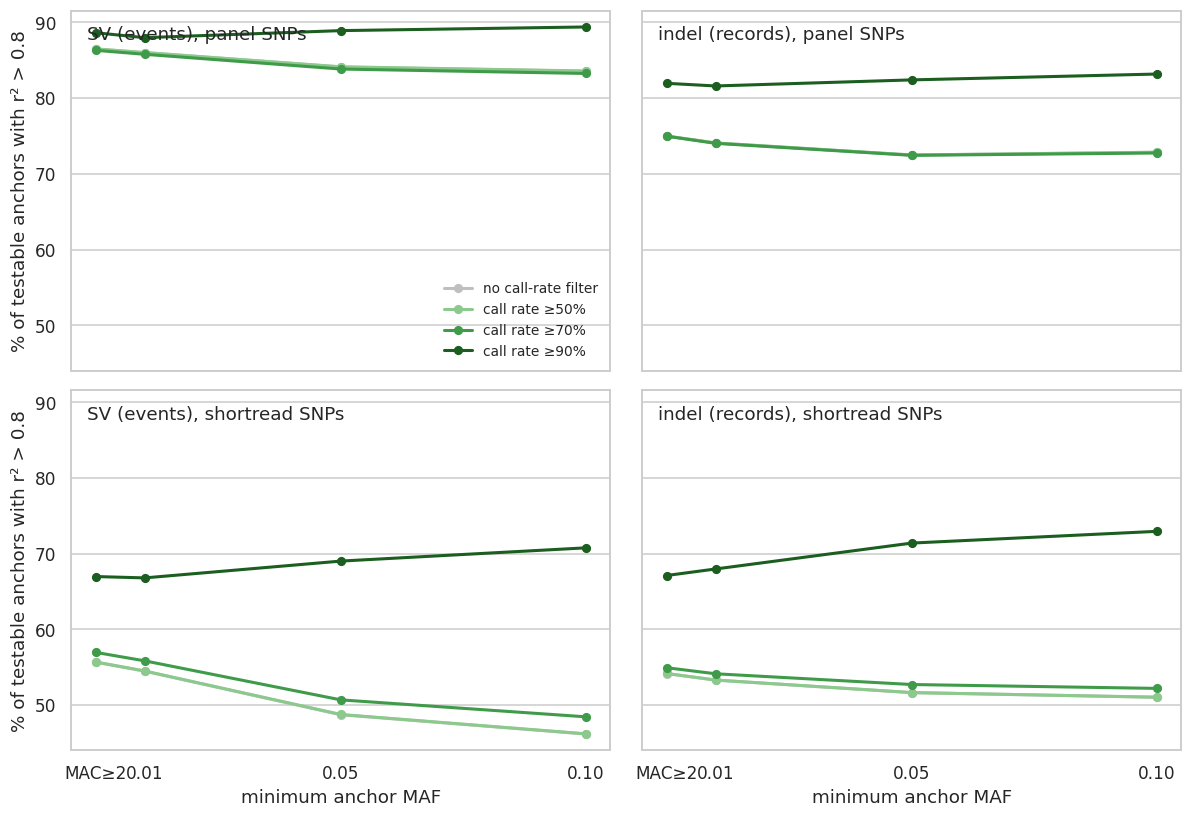

In [4]:
# 3. The same grid transposed: x = MAF floor on the anchor, one line per call-rate floor.
fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), sharey=True, sharex=True)
CRCOL = dict(zip(CALL, ["#BFBFBF", "#8CC98C", "#3F9B49", "#1B5E20"]))
for i, mode in enumerate(["panel", "shortread"]):
    for j, cl in enumerate(CLASS_ORDER):
        ax = axes[i, j]
        for cr in CALL:
            sub = filt[(filt.cls == cl) & (filt.snp_source == mode) & (filt.min_callrate == cr)].sort_values("maf_floor")
            ax.plot(sub.maf_floor, sub.pct_tagged, "-o", color=CRCOL[cr], lw=2, ms=5, label=("no call-rate filter" if cr == 0 else f"call rate ≥{cr}%"))
        ax.annotate(f"{cl} ({'events' if cl == 'SV' else 'records'}), {mode} SNPs", xy=(0.03, 0.92), xycoords="axes fraction")
        ax.grid(axis="x", visible=False); ax.set_xticks([m for m, _ in MAFS]); ax.set_xticklabels(["MAC≥2", "0.01", "0.05", "0.10"])
axes[1, 0].set_xlabel("minimum anchor MAF"); axes[1, 1].set_xlabel("minimum anchor MAF")
axes[0, 0].set_ylabel("% of testable anchors with r² > 0.8"); axes[1, 0].set_ylabel("% of testable anchors with r² > 0.8")
axes[0, 0].legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig(f"{PLOTDIR}/tagging_03_maf_by_callrate.png", dpi=150, bbox_inches="tight"); plt.show()

## 3b. Filter panel: does the survival curve change?

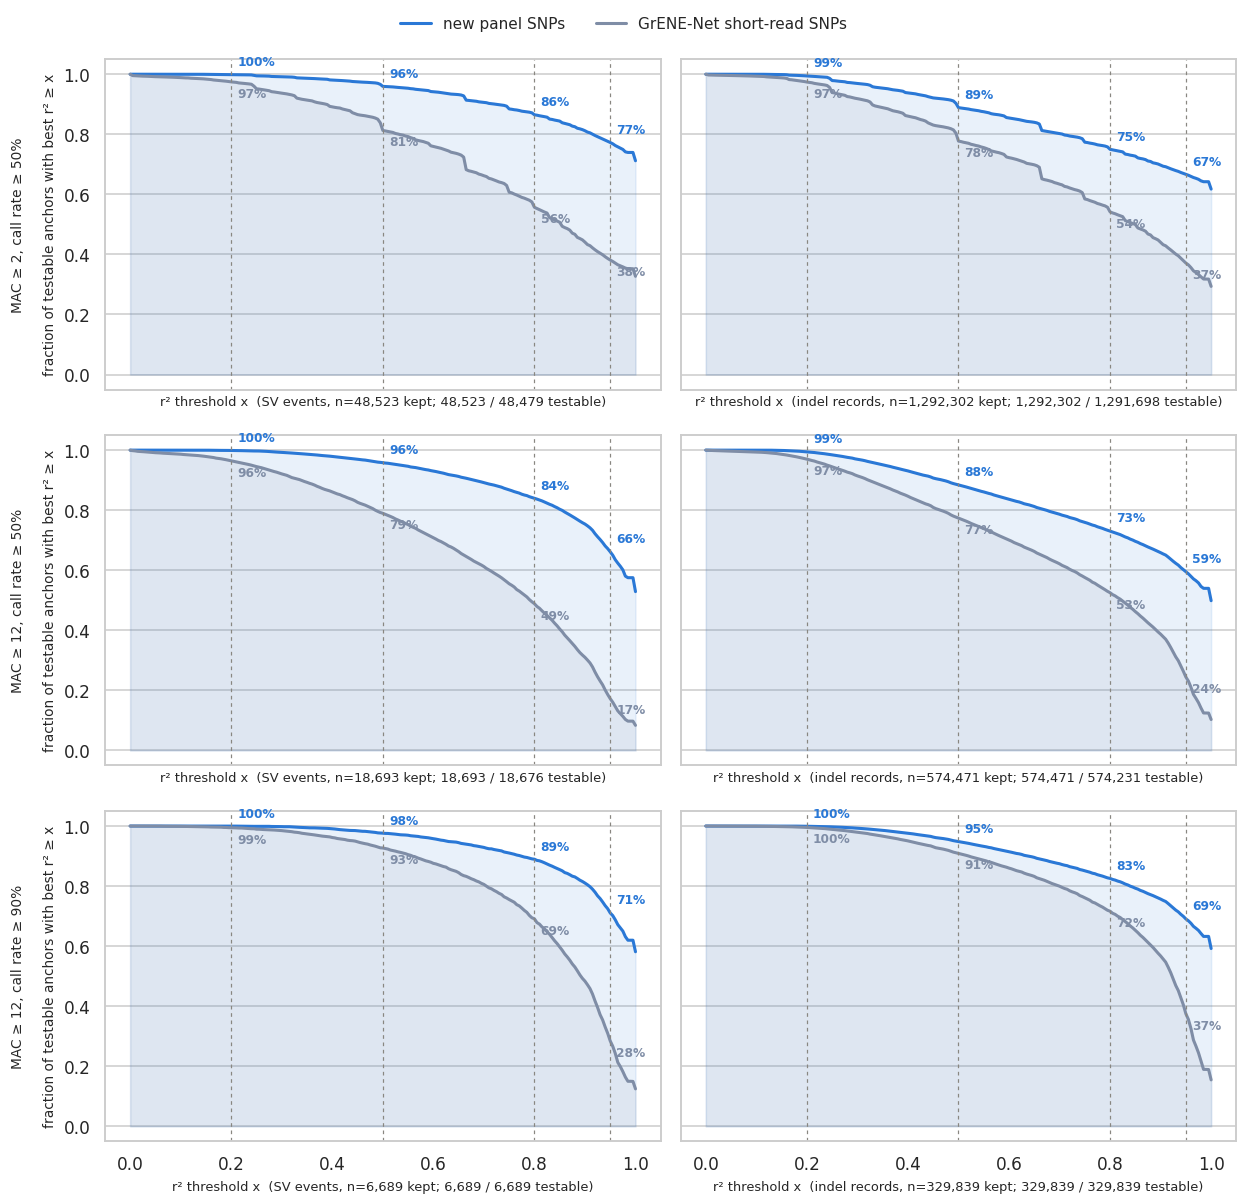

n_kept  testable_panel  testable_short  \
row                       cls                                              
MAC ≥ 2, call rate ≥ 50%  SV       48523           48523           48479   
                          indel  1292302         1292302         1291698   
MAC ≥ 12, call rate ≥ 50% SV       18693           18693           18676   
                          indel   574471          574471          574231   
MAC ≥ 12, call rate ≥ 90% SV        6689            6689            6689   
                          indel   329839          329839          329839   

                                 panel>0.5  panel>0.8  panel>0.95  short>0.5  \
row                       cls                                                  
MAC ≥ 2, call rate ≥ 50%  SV          96.0       86.5        77.3       81.3   
                          indel       88.9       75.0        66.7       77.7   
MAC ≥ 12, call rate ≥ 50% SV          95.8       84.0        66.1       79.0   
                          indel       88.4       73.1        59.5       77.4   
MAC ≥ 12, call rate ≥ 90% SV          97.6       89.0        71.1       92.7   
                          indel       94.8       82.6        69.1       90.9   

                                 short>0.8  short>0.95  
row                       cls                           
MAC ≥ 2, call rate ≥ 50%  SV          55.7        38.1  
                          indel       54.2        37.1  
MAC ≥ 12, call rate ≥ 50% SV          48.9        17.3  
                          indel       52.5        24.5  
MAC ≥ 12, call rate ≥ 90% SV          69.1        28.4  
                          indel       71.6        37.5

In [5]:
# 3b. Filter panel: does the survival curve change with the anchor filters? Rows = filter, columns = SV events | indels.
# MAC = min(alt count, called count - alt count) of the anchor; call rate = % of the 231 founders called at the anchor.
# Anchors and candidate SNPs were computed with MAC >= 2. Curves are over TESTABLE anchors (best r2 defined), per SNP source;
# n = anchors kept; testable anchors for panel SNPs / short-read SNPs.
FP_ROWS = [("MAC ≥ 2, call rate ≥ 50%", lambda d: d[(d.mac >= 2) & (d.callrate >= 50)]),
           ("MAC ≥ 12, call rate ≥ 50%", lambda d: d[(d.mac >= 12) & (d.callrate >= 50)]),
           ("MAC ≥ 12, call rate ≥ 90%", lambda d: d[(d.mac >= 12) & (d.callrate >= 90)])]
xs = np.linspace(0, 1, 201)
fig, axes = plt.subplots(len(FP_ROWS), 2, figsize=(11.5, 11), sharex=True, sharey=True)
fp_rows = []
for i, (lab, fn) in enumerate(FP_ROWS):
    for j, cl in enumerate(CLASS_ORDER):
        ax = axes[i, j]; sub = fn(df[df.cls == cl])
        _p, _s = sub.r2_panel.dropna(), sub.r2_shortread.dropna()
        sp_ = np.array([(_p >= x).mean() for x in xs]); ss_ = np.array([(_s >= x).mean() for x in xs])
        ax.plot(xs, sp_, color=ACCENT, lw=2, label="new panel SNPs"); ax.fill_between(xs, sp_, color=ACCENT, alpha=0.10)
        ax.plot(xs, ss_, color=BASE, lw=2, label="GrENE-Net short-read SNPs"); ax.fill_between(xs, ss_, color=BASE, alpha=0.10)
        for t in (0.2, 0.5, 0.8, 0.95):
            ax.axvline(t, color=INK_MUTED, lw=0.8, ls=(0, (3, 3))); k = np.argmin(np.abs(xs - t))
            ax.annotate(f"{100*sp_[k]:.0f}%", (t, sp_[k]), xytext=(4, 6), textcoords="offset points", fontsize=8, color=ACCENT, fontweight="bold")
            ax.annotate(f"{100*ss_[k]:.0f}%", (t, ss_[k]), xytext=(4, -10), textcoords="offset points", fontsize=8, color=BASE, fontweight="bold")
        ax.set_xlabel(f"r² threshold x  ({cl}{' events' if cl == 'SV' else ' records'}, n={len(sub):,} kept; {len(_p):,} / {len(_s):,} testable)", fontsize=8.5)
        ax.grid(axis="x", visible=False)
        for t, nm in ((0.8, "p80"), (0.95, "p95")): pass
        fp_rows.append({"row": lab.replace("\n", " "), "cls": cl, "n_kept": len(sub), "testable_panel": len(_p), "testable_short": len(_s),
                        "panel>0.5": 100*(_p > 0.5).mean(), "panel>0.8": 100*(_p > 0.8).mean(), "panel>0.95": 100*(_p > 0.95).mean(),
                        "short>0.5": 100*(_s > 0.5).mean(), "short>0.8": 100*(_s > 0.8).mean(), "short>0.95": 100*(_s > 0.95).mean()})
    axes[i, 0].set_ylabel(f"{lab}\n\nfraction of testable anchors with best r² ≥ x", fontsize=9)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.975)); plt.savefig(f"{PLOTDIR}/tagging_06_filter_panel_events.png", dpi=150, bbox_inches="tight"); plt.show()
pd.DataFrame(fp_rows).set_index(["row", "cls"]).round(1)

## 4. Distribution of best r²

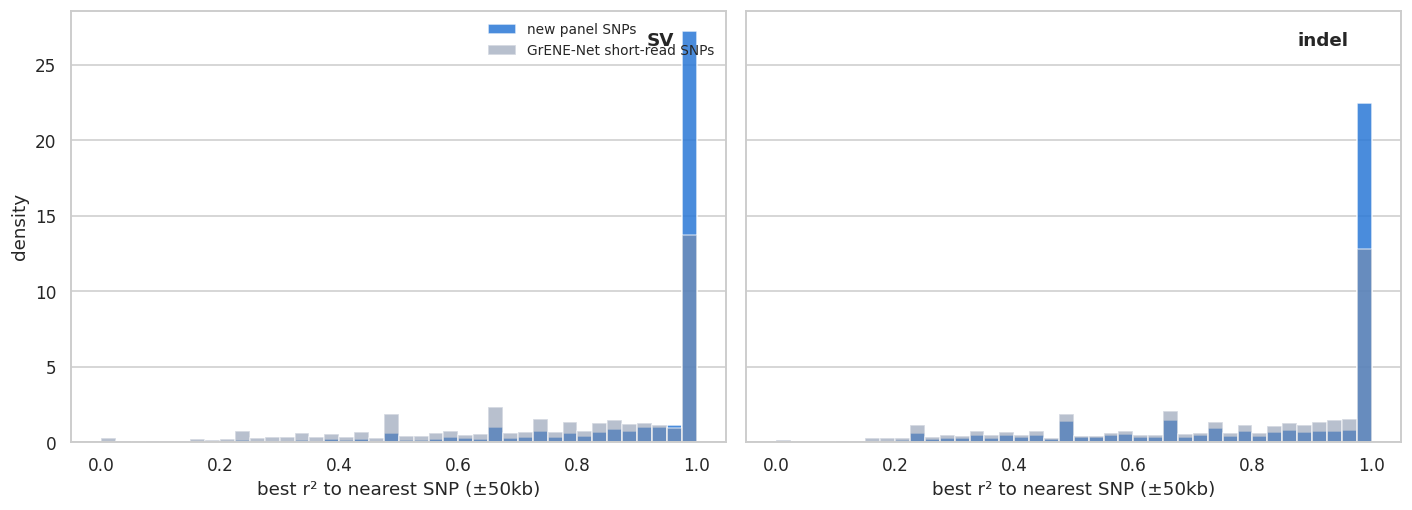

In [6]:
# 4. Distribution of best r2, SV vs indel, panel vs shortread
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, cl in zip(axes, CLASS_ORDER):
    sub = df[df.cls == cl]
    ax.hist(sub.r2_panel.dropna(), bins=bins, color=ACCENT, alpha=0.85, density=True, label="new panel SNPs")
    ax.hist(sub.r2_shortread.dropna(), bins=bins, color=BASE, alpha=0.55, density=True, label="GrENE-Net short-read SNPs")
    ax.annotate(cl, xy=(0.92, 0.92), xycoords="axes fraction", ha="right", fontweight="bold")
    ax.set_xlabel("best r² to nearest SNP (±50kb)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(f"{PLOTDIR}/tagging_04_r2_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Paired per-anchor comparison

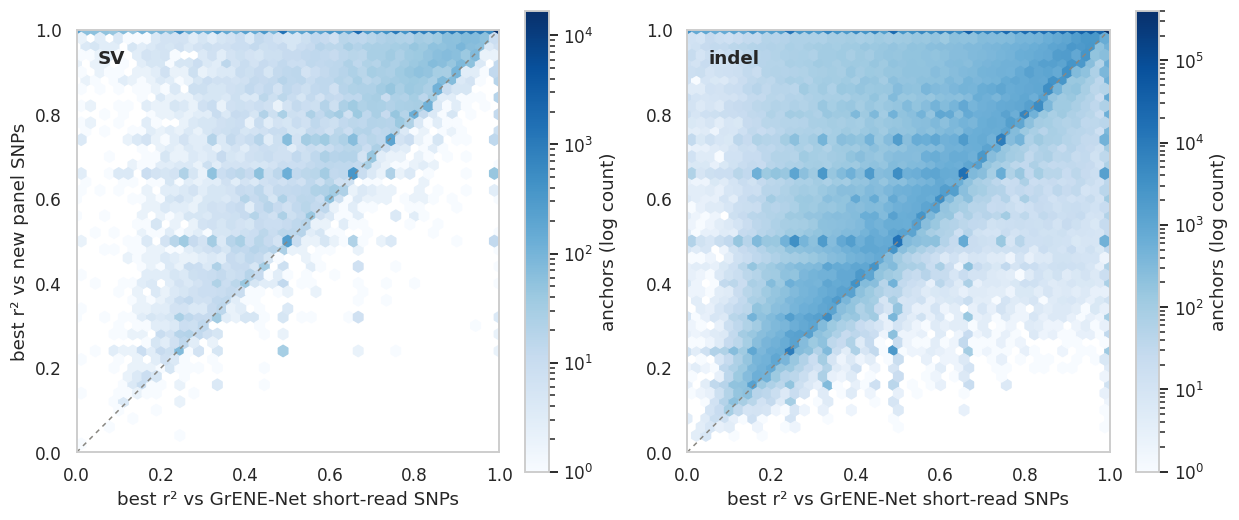

SV: 15,133 of 59,506 (25.4%) cross r²>0.8 with new-panel SNPs but NOT with GrENE-Net short-read SNPs alone
indel: 278,810 of 1,406,721 (19.8%) cross r²>0.8 with new-panel SNPs but NOT with GrENE-Net short-read SNPs alone


In [7]:
# 5. Paired per-anchor comparison: same anchor, panel r2 vs shortread r2
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.6))
for ax, cl in zip(axes, CLASS_ORDER):
    sub = df[df.cls == cl]
    hb = ax.hexbin(sub.r2_shortread, sub.r2_panel, gridsize=45, mincnt=1,
                    cmap="Blues", bins="log", extent=(0, 1, 0, 1))
    ax.plot([0, 1], [0, 1], color=INK_MUTED, lw=1, ls=(0, (3, 3)))
    ax.set_xlabel("best r² vs GrENE-Net short-read SNPs")
    ax.annotate(cl, xy=(0.05, 0.92), xycoords="axes fraction", fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.grid(visible=False)
    fig.colorbar(hb, ax=ax, label="anchors (log count)", shrink=0.8)
axes[0].set_ylabel("best r² vs new panel SNPs")
plt.tight_layout(); plt.savefig(f"{PLOTDIR}/tagging_05_paired.png", dpi=150, bbox_inches="tight"); plt.show()

for cl in CLASS_ORDER:
    sub = df[df.cls == cl]
    n_gain = int(((sub.r2_panel > 0.8) & (sub.r2_shortread <= 0.8)).sum())
    print(f"{cl}: {n_gain:,} of {len(sub):,} ({100*n_gain/len(sub):.1f}%) cross r²>0.8 with new-panel SNPs "
          f"but NOT with GrENE-Net short-read SNPs alone")

## Takeaways

All numbers are computed in the cells above; the filter-grid tables in &sect;2 give the tagging rate at r&sup2;&gt;0.8 for every combination. SV = events, indel = records.
